In [1]:
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
data=np.loadtxt('ex2data1.txt',delimiter=',')
data[:5,:3]

array([[34.62365962, 78.02469282,  0.        ],
       [30.28671077, 43.89499752,  0.        ],
       [35.84740877, 72.90219803,  0.        ],
       [60.18259939, 86.3085521 ,  1.        ],
       [79.03273605, 75.34437644,  1.        ]])

In [3]:
pos=np.where(data[:,2]==1)[0]
neg=np.where(data[:,2]==0)[0]

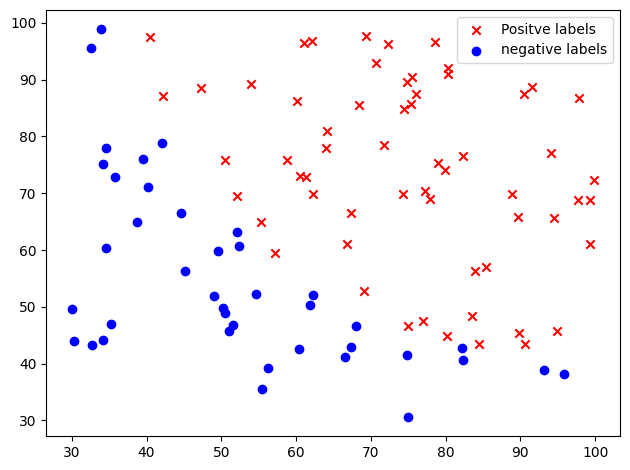

In [4]:
plt.figure()
plt.scatter(data[pos,0],data[pos,1],marker='x',color='r',label='Positve labels')
plt.scatter(data[neg,0],data[neg,1],marker='o',color='b',label='negative labels')
plt.legend(loc='best')
plt.tight_layout()

In [5]:
data.shape

(100, 3)

In [6]:
X_raw=data[:,:2]
y=data[:,2]

#scaling
mu=X_raw.mean(axis=0)
sigma=X_raw.std(axis=0)
X_scaled=(X_raw-mu)/sigma
# X_scaled=X_raw

In [7]:
X_scaled_full=np.c_[np.ones(X_scaled.shape[0]),X_scaled]
X_scaled_full.shape

(100, 3)

In [8]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

def compute_cost(x,y,theta):
    n=y.size
    hypothesis=sigmoid(np.dot(x,theta))
    hypothesis=np.clip(hypothesis,1e-7,1-(1e-7))
    cost=np.sum(-y*np.log(hypothesis)-(1-y)*np.log(1-hypothesis))/n
    return cost

theta_init=np.zeros(X_scaled_full.shape[1])

initial_cost=compute_cost(X_scaled_full,y,theta_init)
initial_cost


np.float64(0.6931471805599453)

In [9]:
max_iter=100
alpha=sorted([10])

learning rate 10 best theta [1.7174089  3.99056564 3.72298639] min cost 0.20349773241278973


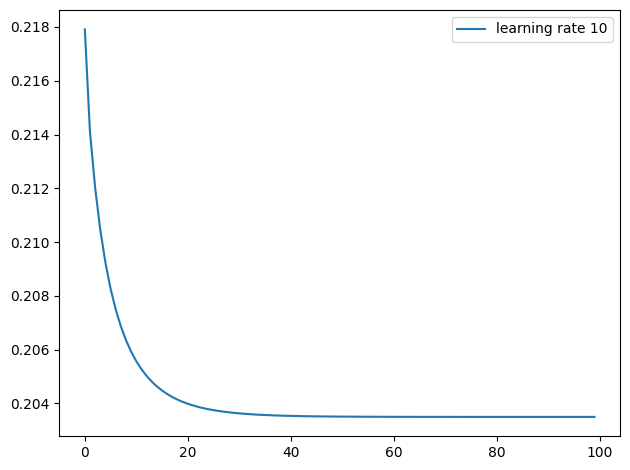

In [10]:


def gradientDescent(x,y,theta,alpha,max_iter):
    n=y.size
    cost_history=[]
    theta_history=[]
    for i in range(max_iter):
        theta=theta.copy()
        residual=(sigmoid(np.dot(x,theta))-y)
        gradient= (x.T @ residual)/n
        theta -= alpha * gradient
        theta_history.append(theta)
        cost=compute_cost(x,y,theta)
        cost_history.append(cost)
    return theta,theta_history,cost_history
plt.figure()
for i in alpha:
    theta,theta_history,cost_history=gradientDescent(X_scaled_full,y,theta_init,max_iter=max_iter,alpha=i)
    plt.plot(range(len(cost_history)),cost_history,label=f'learning rate {i}')
    print(f'learning rate {i} best theta {theta} min cost {cost_history[-1]}')

# plt.yscale('log')
plt.legend()
plt.tight_layout()
    

In [11]:
X_test=[45,85]
X_test_scaled=(X_test-mu)/sigma
X_test_sclaed_full=np.r_[1,X_test_scaled]

prediction=sigmoid(X_test_sclaed_full @theta)
print(f'{float(prediction):.4f}')

0.7761


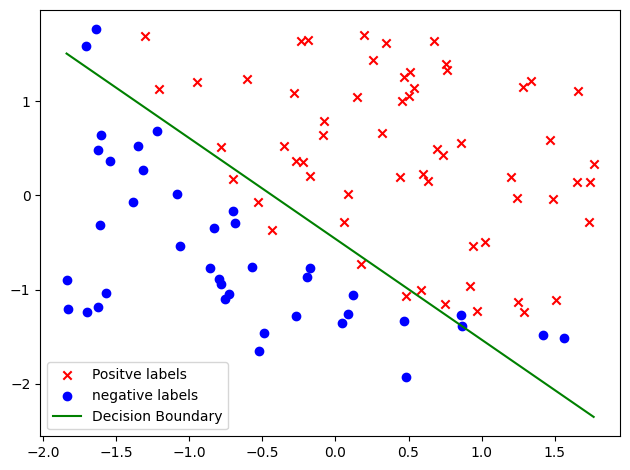

In [13]:
pos= y==1
neg = y==0
plt.figure()
plt.scatter(X_scaled_full[pos,1],X_scaled_full[pos,2],marker='x',color='r',label='Positve labels')
plt.scatter(X_scaled_full[neg,1],X_scaled_full[neg,2],marker='o',color='b',label='negative labels')

x1_vals=np.array([X_scaled_full[:,1].min(),X_scaled_full[:,1].max()])
x2_vals=-(theta[0]+theta[1]*x1_vals)/theta[2]

plt.plot(x1_vals,x2_vals,c='g',label='Decision Boundary')


plt.legend(loc='best')
plt.tight_layout()



array([30.05882245, 99.8278578 ])

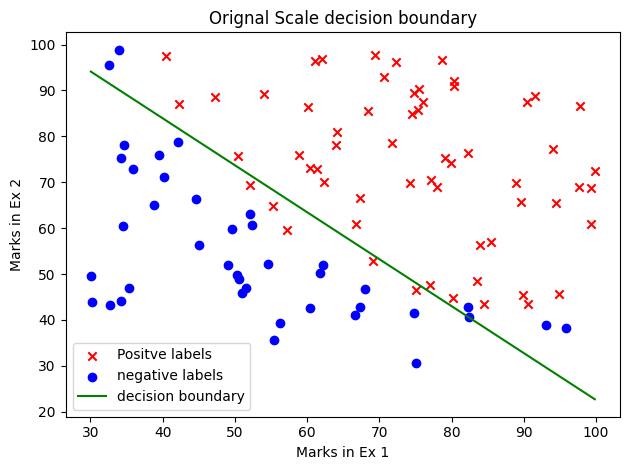

In [ ]:
pos= y==1
neg = y==0
plt.figure()
plt.scatter(X_raw[pos,0],X_raw[pos,1],marker='x',color='r',label='Positve labels')
plt.scatter(X_raw[neg,0],X_raw[neg,1],marker='o',color='b',label='negative labels')

#we need only 2 points to map the line

x1_rawvalues=np.array([X_raw[:,0].min(),X_raw[:,0].max()])
x1_scaledvalues=(x1_rawvalues-mu[0])/sigma[0]
x2_scaled=-(theta[0]+theta[1]*x1_scaledvalues)/theta[2]
x2_rawvalues=(x2_scaled*sigma[1])+mu[1]



plt.plot(x1_rawvalues,x2_rawvalues,c='g',label='decision boundary')
plt.title('Orignal Scale decision boundary')
plt.xlabel('Marks in Ex 1')
plt.ylabel('Marks in Ex 2')
plt.legend()
plt.tight_layout()
x1_rawvalues